# Project 4: Hypothesis Test

## Research Question 
Do quasars have a higher average redshift than galaxies?

## Introduction
Hypothesis testing is a powerful tool in statistics used to use sample data to make decisions or test claims about a larger population. It compares two opposite ideas about a population by using data from a smaller part of that group (a sample). In this project, I will use hypothesis testing to compare the average redshifts between quasars and galaxies, centering around my assumption that quasars have a higher redshift than galaxies. By the end of this project, I want to learn hypothesis testing, statistical significance, and statistical inference.

First, we import libraries and download the data set. Run the cell below.

In [3]:
import pandas as pd
import numpy as np
from numpy import random
import matplotlib.pyplot as plt
import math

sdss17 = pd.read_csv("../data/star_classification.csv")

## Background


Light travels as electromagnetic waves, which have a wavelength and frequency. When light is stretched to longer wavelengths, its frequency decreases, shifting it toward the red end of the electromagnetic spectrum. This phenomenon is known as redshift. In astronomy, redshift can occur when an object is moving away from an observer, but it can also result from the expansion of space itself. The opposite effect is blueshift, which occurs when light is compressed to shorter wavelengths and shifts toward the blue end of the spectrum.

Quasars and galaxies may have different redshift distributions because of differences in their luminosity and how they are detected. Quasars are extremely luminous active galactic nuclei, allowing them to be observed across much greater cosmological distances than many ordinary galaxies. As a result, high-redshift quasars can be detected in surveys even when less-luminous galaxies at similar distances may be too faint to observe. The selection criteria of astronomical surveys can therefore influence the observed redshift distributions of different object classes.

In this project, we will compare the average redshifts of quasars and galaxies in the SDSS17 dataset. We will test whether the data provide statistically significant evidence that quasars have a higher average redshift than galaxies.

## Key Terms
To understand the Hypothesis testing, we will go over key terms.

- Parameter: In Hypothesis testing, acts as the core target of a test
- Signifiance Level $\alpha$: a fixed threshold set before a test and is used to decide if test results are real or due to chance
- p-value: a calculated probability that measures how likely it is that you got your test results by random chance alone
- Test Statistic: a single number calculated from sample data that measures how far your data diverges from what is expected under the null hypothesis, showiing the size of the gap between your observed sample results and the no-effect scenario predicted by the null hypothesis
- Critical Value: a cutoff threshold on a test scale that decides if your results are extreme enough
- T-Test: a statistical test that compares a difference you observed against how much random variation you'd expect

## Defining Hypotheses
When tackling a research question, you should always start by stating your hypotheses. In hypothesis testing, it follows a statistical process, and begins when we state our hypotheses which is split into two kinds.

Our parameter is:
$$ \mu_Q - \mu_G $$
- $\mu_Q$ = population mean redshift of quasars
- $\mu_G$ = population mean redshift of galaxies

Now let's state our hypotheses:
- Null Hypothesis ($H_0$): The starting assumption, or there is no difference in the population mean redshift $$ H_0 : \mu_Q - \mu_G = 0 $$
- Alternative Hypothesis ($H_a$ or $H_1$): The opposite, saying there is a difference, or quasars have a higher population mean redshift than galaxies. $$ H_a : \mu_Q - \mu_G > 0 $$

The Null Hypothesis states there is no effect, no difference, or no relationship between variables, and assumes the current situations remains unchanged. It's directly tested using sample data and written using equality symbols. The Alternative Hypothesis challenges the null hypothesis, and suggests there is an effect, a difference, or a relationship does exist. It represents the research or study claim, and accepted only when the null hypothesis is rejected. It's written using inequality symbols.

Now we can calculate the observed difference, which is the actual gap measured between two groups, samples, or conditions in a study or experiment. An observed difference might show a real effect, or it could happen purely by random chance, and the point of a hypothesis test is to see how likely it is that the observed difference happened by random chance alone. 

<center> Observed difference = $\bar{x}_Q - \bar{x}_G$ </center>

In [8]:
quasars = sdss17[sdss17['class'] == 'QSO']
galaxies =  sdss17[sdss17['class'] == 'GALAXY']

quasar_mean = quasars.redshift.mean()
galaxy_mean = galaxies.redshift.mean()

observed_difference = quasar_mean - galaxy_mean
observed_difference

np.float64(1.2980799388463815)

NOTE. What is the difference between $\mu$ and $\bar{x}$?
Suppose you want to know the average redshift of all quasars in the universe. You can't measure every quasar, so:
- $\mu_Q$ = the true average redshift of the entire quasar population → unknown
- $\bar{x}_Q$ = average redshift of the quasars in our SDSS17 sample → we can calculate this


## Statistical Tests
Hypothesis testing is the overall process, and before we go further, we need to learn the different statistical tests/methods to carry out that process.

Statistical tests are all about calculating a test statistic, a single number calculated from sample data that measures how far your data diverges from what is expected under the null hypothesis. It then calculates a p-value, which estimates how likely it is that you got your test results by random chance alone. If the value of the test statistic is more extreme than the statistic calculated under the null hypothesis, then we can surmise a statistically significant relationship between the predictor variable and the outcome.

Statistical tests can only be performed on data that have been collected in a statistically valid manner, such as through experiments. Additionally, the sample size must be large enough to approximate the true distribution of the population being studied.

#### Statistical Assumptions
Statistical tests make some common assumptions about the data they are testing:
1. Independence of observations
2. Homogeneity of variance
3. Normality of data


#### Types of Variables
The type of statistical test we use can usually be determined by the type of variables we have. 

Categorical data is information that sorts items into groups or categories using labels instead of numbers. There are two types of categorical data.
- Nominal data: groups with no specific order (e.g eye color, gender)
- Ordinal data: groups that follow a sequence of hierarchy (e.g school grades, socioeconomic status)

Quantitative data are data represented numerically and can be measured, counted, and hav artihmetic performed on it, such as ages in a population or salaries in a company.
- Discrete data: whole numbers that you can count (e.g numbers of students in a class, people in a household)
- Continuous data: measurable and within a range (e.g a person's height, a car's speed).

### Parametric Tests
For a parametric test to be valid, your data must generally meet the three above listed statistical assumptions. A parametric test is a statistical hypothesis test that makes specific assumptions about the population distribution of the data.

#### Regression Tests
Regression tests is a statistical method used to find the relationship between a dependent variable and one or more independent variables. It looks for cause-and-effect relationships.

Regression tests are valuable in showing how much an independent variable affects the dependent variable, and allows us to make predictions.

There are three common types:
1. Simple Linear Regression:  uses a single independent variable to predict a continuous outcome using a straight line of best fit
2. Multiple Linear Regression: uses two or more independent variables to predict an outcome
3. Logistic Regression: predicts categorical outcomes, such as a "yes or no" choice, by calculating the probability of an event

#### Z-Test
A z-test is a statistical test used to determine whether two population means are different, and is used when the population standard deviation is known and the sample size is large. Z-test is used to validate a hypothesis that the sample drawn belongs to the same population.

- Null Hypothesis ($H_0$): Sample mean is the same as the population mean
- Alternative Hypothesis ($H_a$ or $H_1$): Sample mean is not the same as the population mean

The z-value can be calculated by $$ z = \frac{(\bar{x} - \mu)}{\frac{\sigma}{\sqrt{n}}} $$

where $\bar{x}$ = sample mean, $\mu$ = population mean, $\sigma$ = population standard deviation, and n = sample size.

If z value is less than critical value, accept the null hypothesis, otherwise reject null hypothesis.

#### T-Test
A t-test is a statistical test used to find out if the averages of two groups are different from each other or from a known value.

There are three main types of T-Tests:
- One-Sample T-Test: Compares the average of one group to a specific, known number
- Independent Two-Sample T-Test: Compares the averages of two totally separate groups (like test scores for two different classes)
- Paired T-Test:  Compares measurements taken from the same group twice, such as before and after a treatment

The t-value for a one-sample t-test can be calculated by $$ t = \frac{\bar{x} - \mu}{\frac{s}{\sqrt{n}}} $$

where $\bar{x}$ = observed mean of the sample, $\mu$ = the population mean, s = sample standard deviation, and n = sample size

The t-value for an independent two-sample t-test can be calculated by $$ t = \frac{\bar{x}_1 - \bar{x}_2}{s_p \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}}$$

where $\bar{x}_1$, $ \bar{x}_2$ = means of group 1 and group 2, $n_1$, $n_2$ = sample sizes of group 1 and group 2, and $s_p$ = pooled standard deviation calculated from both groups.

The t-test for paired samples t-Test can be calculated by $$ t = \frac{\bar{d}}{\frac{s_d}{\sqrt{n}}}$$

where $\bar{d}$ = mean of the differences between the paired valyes, $s_d$ = the standard deviation of the differences, and n = number of pairs.

### Non-Parametric Tests
A non-parametric test is a statistical test or model that does not assume the data follows a specific probability distribution, suhc as a normal distribution.

#### Chi-Square Test
A Chi-Squared ($\chi^2$) test is a statistical method used to determine if there is a significant difference between observed data and expected data in categorical variables by checking if actual counted data matches expected patterns or theoretical predictions. 

In categorical data analysis, the chi-square test compares observed frequencies with expected ones under a given hypothesis. The chi-square test calculates a test statistic, denoted as $\chi^2$. If large enough, we can reject the null hyptohesis $H_0$. 

The test statistic can be calculated by $$\chi^2 = \sum \frac{(O_i - E_i)^2}{E_i}$$

where $O_i$ = Observed frequency, and $E_i$ = Expected frequency

To find the observed frequency, you collect your raw data, count the frequency or how many times each category or outcome appears, and create a contigency table. 

The expected frequency is the number of times you would expect a specific outcome to occur if a certain assumption is true, and the formula you use for it depends on the type of test you are performing:
1. Chi-Square Goodness-of-Fit Test: for a single categorical variable against a set of expected probabilities $$ E = n \times p_i $$ where n = total number of observations and $p_i$ is the theortical probability of category $i$
2. Chi-Square Test of Independence: for when you want to test whether two categorical variables are related or independent $$ E = \frac{Row Total \times Column Total}{Grand Total(N)} $$ 

Compare the test statistic with the critical value from the Chi-Square distribution table. If the p-value is less than a certain signifiance level, then reject the null hypothesis. Thus, the catgeory variables highly correlate with each other.

It's importanrt to remember that Chi-Square tests indicates an association between variables, NOT a causal relationship.

#### Permutation Test
Permutation tests are another type of a non-paramtric test statistical method that determines the likelihood of an obserbed difference between groups by repeatedly shuffling data labels to build an empirical null distribution.

## Null Distributions
A null distribution is the probability distribution of the test statistic calculated under the assumption that the null hypothesis is true. If quasars and galaxies actually had the same population mean redshift, how large of a difference could we get just from random chance?

Suppose quasars and galaxies don't actually differ in average redshift. If we calculate the observed difference many, many, many times, most differences should be relatively close to zero because we're assuming there is no real difference. If you plot thousands of those differences, we get the null distribution. It's the distribution of differences we'd expect if there were no real difference.

One way to create one is a permutation test, which will be the test we're using this project.

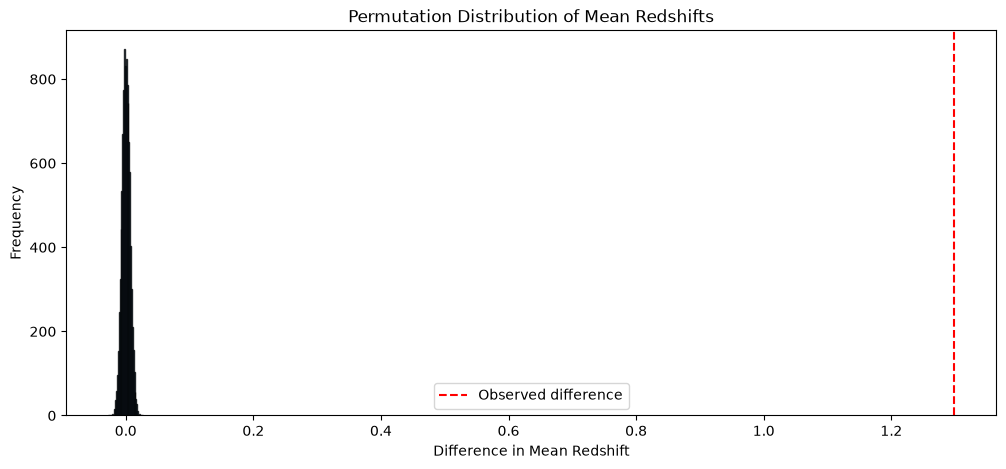

Observed difference: 1.2980799388463815
Permutation minimum: -0.027118461183263554
Permutation maximum: 0.02742863740870438


In [20]:
all_redshifts = pd.concat([quasars.redshift, galaxies.redshift])

n_quasars = len(quasars.redshift)
n_galaxies = len(galaxies.redshift)

permutation_differences = []

for i in range(10000):
    shuffled = all_redshifts.sample(   # Randomly selects rows from a Series or DataFrame
        frac=1,  # Selects 100% of the rows
        replace=False   # Every redshift appears exactly once
    ).reset_index(drop=True)  # Doesn't keep the old indexes and gives them new clean ones
    
    # Remember that .iloc means to select rows by their position
    random_quasars = shuffled.iloc[:n_quasars]  # Takes the first n_quasars rows
    random_galaxies = shuffled.iloc[n_quasars:] # Start at n_quarters and take everything after that
    
    difference = random_quasars.mean() - random_galaxies.mean()
    permutation_differences.append(difference)

plt.figure(figsize=(12,5))

plt.hist(
    permutation_differences,
    bins=40,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    observed_difference,
    color="red",
    linestyle="--",
    label="Observed difference"
)

plt.title("Permutation Distribution of Mean Redshifts")
plt.xlabel("Difference in Mean Redshift")
plt.ylabel("Frequency")

plt.legend()

plt.show()

print("Observed difference:", observed_difference)
print("Permutation minimum:", min(permutation_differences))
print("Permutation maximum:", max(permutation_differences))

Interpretation: The null distribution is centered around 0 because the permutations represent a world where there is no difference between quasars and galaxies. The observed difference is far to the right, suggesting that the observed difference is unusual under the null hypothesis.

## P-Value
Remember that a p-value is a calculated probability that measures how likely it is that you got your test results by random chance alone.

A p-value is a number between 0 and 1 like all probabilities. A lower p-value (closer to 1) indicates that your data is unlikely to have happened by random chance alone, and a larger p-value means your result could have easily happened purely by random luck.

Researchers pick a cutoff point, or the alpha level ($\alpha$) during a test. A very common one is 0.05 or 5%, and we will be picking that as well.

Remember our alternative hypothesis:

 $$ H_a : \mu_Q - \mu_G > 0 $$

This shows we have a one-sided (right-tailed) test. What proportion of our permutation differences were as large as or larger than the actual observed difference?

We can calculate a p-value from a permutation test through

$$ p-value = \frac{B_{extreme} + 1}{B + 1} $$

NOTE: Adding 1 to both the numerator and denominator acts as a correction (pseudo-count). This prevents a p-value of exactly 0 and guarantees the test remains valid and unbiased.

$ B_{extreme} $ counts how many times the test statistic from the shuffled data was greater than or equal to our observed statistic, which in our case is 1.29.


In [24]:
extreme_count = sum(
    difference >= observed_difference
    for difference in permutation_differences
)

p_value = extreme_count + 1 / (len(permutation_differences) + 1)

print(f"p-value: {p_value:.5f}")

p-value: 0.00010


## Statistical Decision
Because the p-value (p≈0.0001) is less than the significance level (α=0.05), we reject the null hypothesis. The SDSS17 data provide statistically significant evidence that quasars have a higher average redshift than galaxies.

NOTE: Don't say the p-value is the probability that $H_0$ is true. We say: Assuming the null hypothesis is true, the probability of obtaining a result at least as extreme as the observed result is approximately 0.01%. 

Additionally, to reject a hypothesis doesn't mean the hypothesis is definitely true. We only found that the data is sufficiently inconsistent with that hypothesis. Also, our test establishes evidence of an association/difference, not necessarily causation.

Checklist:
- Did I state what the data actually showed?
- Did I compare p with α?
- Did I say "reject" or "fail to reject," rather than "prove" or "accept"?
- Did I explain the p-value correctly?
- Did I avoid claiming causation?
- Did I avoid generalizing beyond my population/sample?
- Did I distinguish statistical significance from scientific importance?

## Type I and Type II Errors
Type 1 and Type 2 errors are two different mistakes made during statistical hypothesis testing when deciding whether to accept or reject a null hypothesis. Now that we've actually done the test, we could learn what could have gone wrong.

A Type I error (false positive) occurs when the null hypothesis is incorrectly rejected, even though it is actually true. A Type II error (false negative) occurs when the null hypothesis is not rejected even though it is actually false. The risk of making these errors cannot be completely eliminated. However, the likelihood of one type of error can be adjusted relative to the other by changing the significance threshold.


For our actual hypothesis
- Type I Error: We reject the null hypothesis and conclude that quasars have a higher average redshift than galaxies, when in reality there is no difference in their population mean redshifts.
- Type II Error: We fail to reject the null hypothesis and conclude that there is insufficient evidence of a higher quasar mean redshift, when in reality quasars do have a higher population mean redshift.

Because we rejected the null hypothesis, the relevant potential error is a Type I error. This would occur if the null hypothesis were actually true despite our statistically significant result. We cannot determine whether a Type I error actually occurred because the true population parameters are unknown. Our choice of α=0.05 establishes the significance threshold used to control the Type I error rate.

By choosing a significance level of α=0.05, we are using a threshold that allows a 5% Type I error rate in the long run when the null hypothesis is true. Making the significance threshold smaller makes it harder to reject $H_0$, which reduces the risk of a Type I error but can increase the risk of a Type II error. Conversely, using a larger significance threshold makes it easier to reject $H_0$, reducing the chance of a Type II error but increasing the risk of a Type I error.

Although our permutation test produced a very small p-value, there is still uncertainty in statistical inference. A statistical test cannot guarantee that its conclusion is correct; it provides evidence based on the available sample and the assumptions of the analysis.

## Conclusion


In this project, we investigated whether quasars have a higher average redshift than galaxies using the SDSS17 dataset. We compared the sample mean redshifts of the two groups and used a permutation test to determine whether the observed difference could reasonably be explained by random variation.

The observed difference in mean redshift was approximately 1.3. After randomly shuffling the group labels 10,000 times, none of the simulated differences were as large as the observed difference. This produced a permutation p-value of approximately 0.0001. Since this is smaller than our significance level of α=0.05, we rejected the null hypothesis.

Therefore, the SDSS17 data provide statistically significant evidence that quasars have a higher average redshift than galaxies in this sample. This result is consistent with the fact that quasars are extremely luminous and can be detected across much greater cosmological distances, while many less-luminous galaxies are less likely to be observed at high redshifts. However, the statistical test establishes evidence of a difference in the observed sample; it does not by itself establish causation or explain all of the reasons for the different redshift distributions.

Overall, this project demonstrated how hypothesis testing can be used to evaluate a scientific question by comparing an observed result to what would be expected under the null hypothesis.